# 1 · Black-Scholes pricing, Greeks and implied volatility
Closed-form European option values, the full set of analytic Greeks, a put-call parity check, and implied volatilities backed out of a live option chain.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
from derivpricer import black_scholes as bs

## Pricing and put-call parity

In [2]:
S0, K, T, r, sigma = 100, 100, 0.5, 0.045, 0.25
call, put = bs.price(S0, K, T, r, sigma, "call"), bs.price(S0, K, T, r, sigma, "put")
print(f"ATM call = {call:.4f}   ATM put = {put:.4f}")
print(f"Parity gap C - P - (S - K e^-rT) = {bs.put_call_parity_gap(call, put, S0, K, T, r):.2e}")

ATM call = 8.1335   ATM put = 5.9086
Parity gap C - P - (S - K e^-rT) = 7.11e-15


## Greeks across the strike range
Gamma and vega peak at-the-money; delta moves from 1 to 0 for calls (0 to -1 for puts).

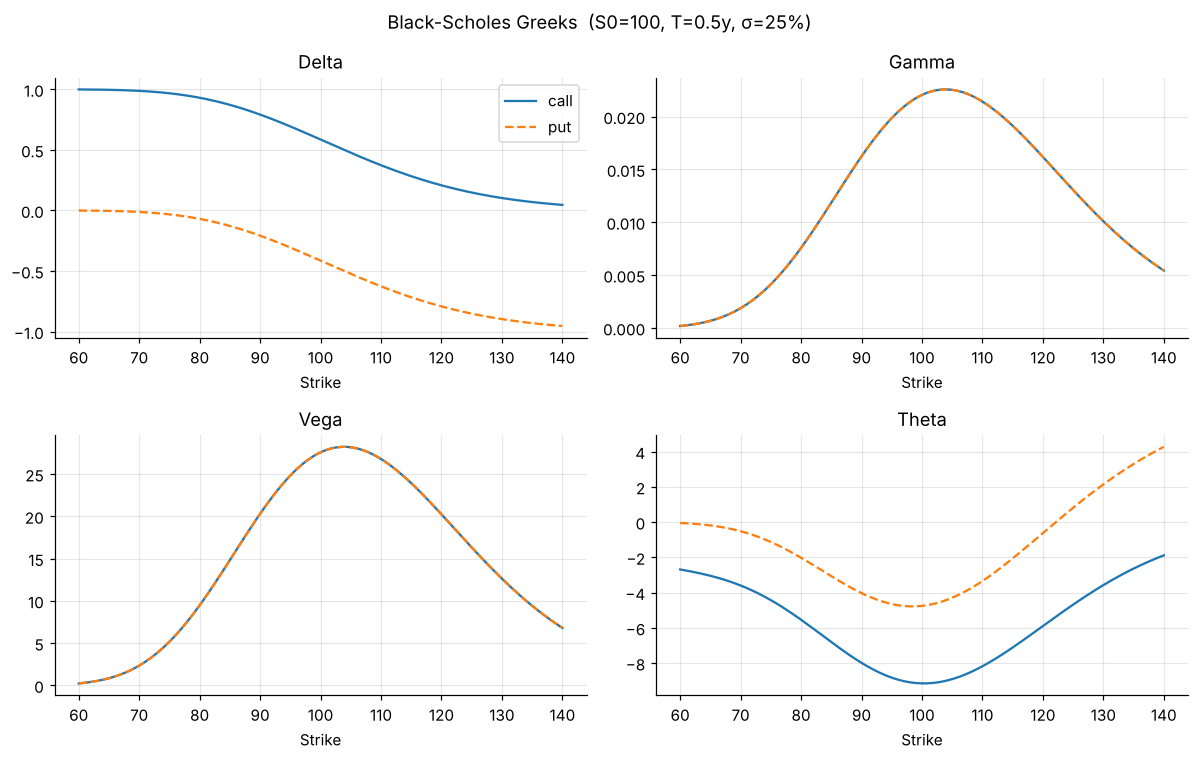

In [3]:
strikes = np.linspace(60, 140, 161)
g_call = bs.greeks(S0, strikes, T, r, sigma, "call"); g_put = bs.greeks(S0, strikes, T, r, sigma, "put")
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, name in zip(ax.flat, ["delta", "gamma", "vega", "theta"]):
    a.plot(strikes, getattr(g_call, name), label="call")
    a.plot(strikes, getattr(g_put, name), "--", label="put")
    a.set_title(name.capitalize()); a.set_xlabel("Strike")
ax[0, 0].legend(); fig.suptitle(f"Black-Scholes Greeks  (S0={S0}, T={T}y, σ={sigma:.0%})"); fig.tight_layout()
fig.savefig(IMG / "bs_greeks.png", bbox_inches="tight"); plt.show()

## Option value vs spot for several maturities

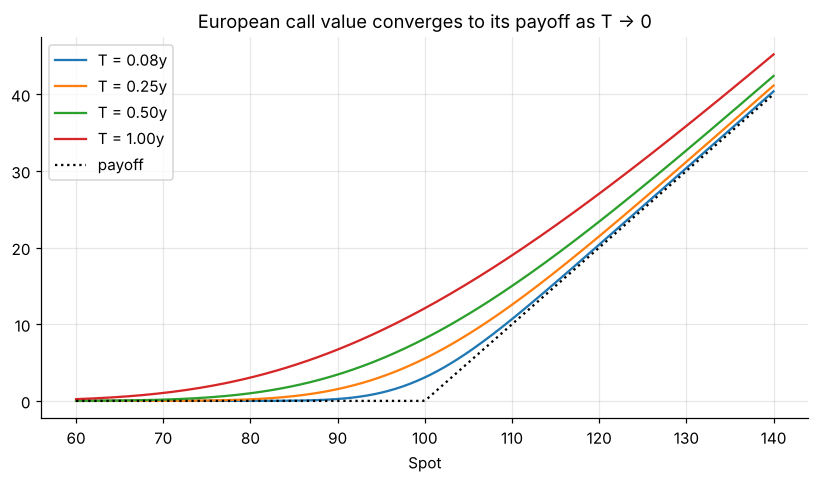

In [4]:
spots = np.linspace(60, 140, 200)
for t in (1/12, 0.25, 0.5, 1.0):
    plt.plot(spots, bs.price(spots, K, t, r, sigma), label=f"T = {t:.2f}y")
plt.plot(spots, np.maximum(spots - K, 0), "k:", label="payoff")
plt.title("European call value converges to its payoff as T → 0"); plt.xlabel("Spot"); plt.legend(); plt.show()

## Implied volatility from a real option chain
SPY call prices are inverted through Brent's method to get implied volatilities.

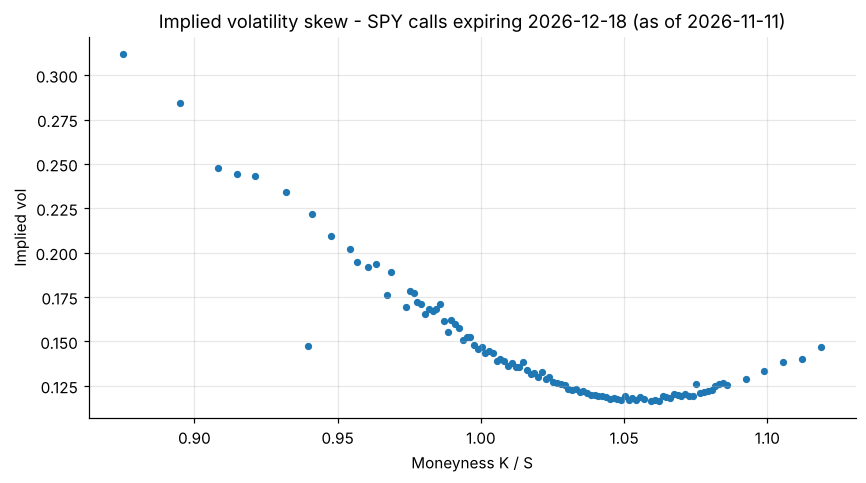

,strike,mid,iv
0,665.0,99.12,0.311681
1,680.0,84.65,0.284088
2,690.0,74.33,0.247961
3,695.0,69.77,0.244260
4,700.0,65.41,0.243407


In [5]:
# Market snapshot saved by scripts/fetch_market_data.py (refresh it to use today's quotes)
snap = pd.read_csv("../data/spy_call_surface.csv")
first = snap[snap.expiry == snap.expiry.iloc[0]]
spot, T_chain = first.spot.iloc[0], first.maturity.iloc[0]
chain = first[["strike", "price"]].rename(columns={"price": "mid"}).reset_index(drop=True)
label = f"SPY calls expiring {first.expiry.iloc[0]} (as of {first["asof"].iloc[0]})"
r, q = 0.041, 0.013  # 3m T-bill yield and SPY dividend yield
chain["iv"] = [bs.implied_vol(p, spot, k, T_chain, r, q=q) for k, p in zip(chain.strike, chain.mid)]
chain = chain.dropna()
plt.scatter(chain.strike / spot, chain.iv, s=14)
plt.title(f"Implied volatility skew - {label}"); plt.xlabel("Moneyness K / S"); plt.ylabel("Implied vol")
plt.savefig(IMG / "iv_skew.png", bbox_inches="tight"); plt.show()
chain.head()

**Takeaway:** a flat Black-Scholes volatility cannot reproduce the downward-sloping equity skew. That motivates the stochastic-volatility and jump models in notebooks 3-4.